# Ahn et al. (2020): torque sensing with a levitated nanorotor, in silico

J. Ahn, Z. Xu, J. Bang, P. Ju, X. Gao and T. Li, *Ultrasensitive torque detection with an optically
levitated nanorotor*, Nat. Nanotechnol. **15**, 89 (2020),
[doi:10.1038/s41565-019-0605-9](https://doi.org/10.1038/s41565-019-0605-9) (open version:
arXiv:1908.03453v1).

A silica nanosphere spins in a circularly polarised tweezer at high vacuum. A second, power-modulated
laser adds a small torque $M_\mathrm{ac}\sin\omega_m t$, which modulates the rotation rate
$\omega_r$ through $I\dot\omega_r = M_\mathrm{dc} + M_\mathrm{ac}\sin\omega_m t + M_\mathrm{th} - I\gamma\omega_r$
(their Eq. (1)). The torque is read from the one-sided spectrum of $\omega_r$ (their Eq. (2)),

$$S_f(\omega) = \frac{4k_BT\gamma}{I(\omega^2+\gamma^2)} + \frac{M_\mathrm{ac}^2\,\Delta t\,\mathrm{sinc}^2[(\omega-\omega_m)\Delta t/2]}{2I^2(\omega^2+\gamma^2)},$$

and the thermal noise sets the sensitivity $\sqrt{4k_BTI\gamma}$ and the smallest torque
$M_\mathrm{min} = \sqrt{4k_BTI\gamma/\Delta t}$ resolvable in a measurement time $\Delta t$.

This notebook repeats the measurement **in silico** with `RigidBodySimulation`: a silica sphere with
levisim's rotational gas friction and its fluctuation-dissipation torque noise, driven by a
modulated external torque (`torque_drive`). The rotation rate is the lab angular velocity about the
beam axis; the torque and the sensitivity are extracted from simulated traces with the paper's
Eq. (2), and compared with

**Comparison stated before running:** the published sensitivity **(4.2 ± 1.2) × 10⁻²⁷ N m/√Hz** at room
temperature (abstract of the published version; the arXiv v1 text gives a measured 6 × 10⁻²⁷ and a
thermal limit of 3 × 10⁻²⁷ N m/√Hz at 10⁻⁵ torr, 300 K), and the smallest measured torque
(1.2 ± 0.5) × 10⁻²⁷ N m in 100 s. levisim's thermal limit $\sqrt{4k_BTI\gamma}$ should reproduce the
paper's thermal estimate; the measured value is expected to lie somewhat above it (technical noise).

## Parameters and where they come from

| Quantity | Value used | Source |
|---|---|---|
| particle | silica sphere, diameter 150 nm, fused silica, ρ = 2200 kg/m³ | Fig. 2 caption ("diameters ... about 150 nm") |
| pressure | 10⁻⁵ torr for the sensitivity; 9.4 × 10⁻⁶ and 1.5 × 10⁻⁵ torr in Fig. 3 | text, Fig. 3 caption |
| temperature | 300 K | text |
| measurement time | 100 s | text |
| damping | levisim's Martinetz rotational friction, full accommodation (the paper measures γ, Fig. 3b) | levisim |

The simulation runs at a higher pressure, 10⁻² torr, where $1/\gamma$ is 18 ms instead of 18 s, so that
a record of many damping times fits in 2 × 10⁶ steps. The extraction is the same at any pressure,
and in the free-molecular regime $\gamma \propto p$ exactly, so the sensitivity at 10⁻⁵ torr follows
from the one measured in silico by $\sqrt{p}$ scaling (the notebook also checks it directly against
$\sqrt{4k_BTI\gamma}$ at the simulated pressure). The sphere's rotation about $z$ does not depend on its
orientation or on the trap, so the dc rotation (GHz in the experiment) is left out ($M_\mathrm{dc} = 0$)
and the tweezer power is lowered to 1 mW to keep the translational motion resolved at the large time
step; neither changes $\omega_r - \omega_\mathrm{dc}$.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import periodogram, welch

from levisim.core.constants import kB, π
from levisim.core.logger import logger
from levisim.core.plotting import set_plt_rcParams_to_xmgrace_style
from levisim.core.units import mbar, mW, nm
from levisim.physics import Gas, Sphere, Trap, Tweezer
from levisim.physics.materials import FUSED_SILICA
from levisim.simulation import RigidBodySimulation

logger.remove()
set_plt_rcParams_to_xmgrace_style()
t_start = time.time()
torr = 1.33322 * mbar
T = 300.0

sphere = Sphere(r=75*nm, material=FUSED_SILICA, λ=1550*nm)
I = sphere.inertia_tensor[2, 2]


def γ_rot(p):
    return sphere.rotational_damping_tensor(Gas(P=p, T=T))[2, 2]


def thermal_sensitivity(p):
    return np.sqrt(4 * kB * T * I * γ_rot(p))


for p in (9.4e-6, 1e-5, 1.5e-5):
    print(f'{p:.1e} torr: γ = {γ_rot(p * torr):.4f} /s (1/γ = {1 / γ_rot(p * torr):.1f} s), '
          f'thermal sensitivity √(4kBTIγ) = {thermal_sensitivity(p * torr):.2e} N m/√Hz, '
          f'M_min(100 s) = {thermal_sensitivity(p * torr) / 10:.2e} N m')
print(f'm = {sphere.m:.3e} kg, I = {I:.3e} kg m²')

9.4e-06 torr: γ = 0.0516 /s (1/γ = 19.4 s), thermal sensitivity √(4kBTIγ) = 2.73e-27 N m/√Hz, M_min(100 s) = 2.73e-28 N m
1.0e-05 torr: γ = 0.0548 /s (1/γ = 18.2 s), thermal sensitivity √(4kBTIγ) = 2.82e-27 N m/√Hz, M_min(100 s) = 2.82e-28 N m
1.5e-05 torr: γ = 0.0823 /s (1/γ = 12.2 s), thermal sensitivity √(4kBTIγ) = 3.45e-27 N m/√Hz, M_min(100 s) = 3.45e-28 N m
m = 3.889e-18 kg, I = 8.751e-33 kg m²


levisim's thermal limit at 10⁻⁵ torr, 2.8 × 10⁻²⁷ N m/√Hz, agrees with the paper's 3 × 10⁻²⁷ N m/√Hz
(they used their measured damping time). The thermally limited smallest torque in 100 s is
2.8 × 10⁻²⁸ N m.

## The measurement in silico

At 10⁻² torr: a modulated torque $M_\mathrm{ac}\sin\omega_m t$ about $z$ at $\omega_m/2\pi$ = 10 Hz
(the paper modulates at 0.2 Hz with $\gamma/2\pi$ ≈ 0.009 Hz; here $\omega_m/\gamma$ ≈ 1.1, of the same
order), for several amplitudes around the thermal limit of a 1 s record.

In [2]:
p_sim = 1e-2 * torr
γ = γ_rot(p_sim)
Δt, n_steps = 5e-7, 2_000_000
duration = Δt * n_steps
ω_m = 2 * π * 10.0
M_min_sim = np.sqrt(4 * kB * T * I * γ / duration)
print(f'simulated: p = 1e-2 torr, γ = {γ:.2f} /s (1/γ = {1e3 / γ:.1f} ms), record {duration:.1f} s, '
      f'thermal M_min = {M_min_sim:.2e} N m, sensitivity {thermal_sensitivity(p_sim):.2e} N m/√Hz')


def run(M_ac, seed):
    trap = Trap(tweezer=Tweezer(λ=1550*nm, Power=1*mW), particle=sphere, gas=Gas(P=p_sim, T=T),
            finite_size_torque=False)  # a sphere: no finite-size torque
    sim = RigidBodySimulation(trap=trap, num_samples=n_steps, Δt=Δt, seed=seed,
                              torque_drive={'amplitude': (0.0, 0.0, M_ac), 'ω': ω_m, 'phase': -π/2})
    ω_r = sim.angular_velocities_lab()[:, 2]
    return sim, ω_r - ω_r.mean()


def periodogram_at_drive(ω_r):
    f, S = periodogram(ω_r, fs=1 / Δt, window='boxcar')
    i = np.argmin(np.abs(f - ω_m / (2 * π)))
    return f, S, S[i], 2 * π * f[i]


def torque_from_power(S_peak, ω):
    """Eq. (2): the peak of the one-sided periodogram at ω_m above the thermal floor"""
    floor = 4 * kB * T * γ / (I * (ω**2 + γ**2))
    excess = max(S_peak - floor, 0.0)
    return np.sqrt(2 * I**2 * (ω**2 + γ**2) * excess / duration)


# each amplitude: four independent 1 s records, their periodograms at ω_m averaged (as a longer
# measurement would); the undriven records also give the noise
amplitudes = np.array([0.0, 1.0, 3.0, 10.0]) * M_min_sim
num_records = 4
results = []
undriven = []
for index, M_ac in enumerate(amplitudes):
    peaks = []
    for record in range(num_records):
        sim, ω_r = run(M_ac, seed=100 * index + record)
        f, S, S_peak, ω_bin = periodogram_at_drive(ω_r)
        peaks.append(S_peak)
        if M_ac == 0:
            undriven.append(ω_r)
    M_est = torque_from_power(np.mean(peaks), ω_bin)
    results.append((M_ac, M_est, f, S))
    print(f'M_ac = {M_ac:.3e} N m ({M_ac / M_min_sim:4.1f} M_min of one record): recovered {M_est:.3e} N m '
          f'from {num_records} records; backend {sim.backend_used}')
equipartition = np.mean([np.var(ω_r) for ω_r in undriven]) * I / (kB * T)
print(f'equipartition check without drive ({num_records} records of {duration * γ:.0f}/γ): I〈ω²〉/kBT = {equipartition:.3f}')

simulated: p = 1e-2 torr, γ = 54.84 /s (1/γ = 18.2 ms), record 1.0 s, thermal M_min = 8.92e-26 N m, sensitivity 8.92e-26 N m/√Hz
M_ac = 0.000e+00 N m ( 0.0 M_min of one record): recovered 0.000e+00 N m from 4 records; backend numba
M_ac = 8.917e-26 N m ( 1.0 M_min of one record): recovered 5.413e-26 N m from 4 records; backend numba
M_ac = 2.675e-25 N m ( 3.0 M_min of one record): recovered 2.449e-25 N m from 4 records; backend numba
M_ac = 8.917e-25 N m (10.0 M_min of one record): recovered 8.455e-25 N m from 4 records; backend numba
equipartition check without drive (4 records of 55/γ): I〈ω²〉/kBT = 0.974


## Sensitivity from the simulated noise

The torque-referred noise of the undriven record, $\sqrt{S_f(\omega)}\,I\sqrt{\omega^2+\gamma^2}$, is
flat (white torque noise) and equals $\sqrt{4k_BTI\gamma}$:

in silico torque sensitivity (1-200 Hz) at 1e-2 torr: 9.164e-26 N m/√Hz; √(4kBTIγ) = 8.917e-26 (ratio 1.028)
scaled to 1e-5 torr (γ ∝ p): 2.90e-27 N m/√Hz; paper: thermal limit 3e-27, measured (4.2 ± 1.2)e-27 N m/√Hz


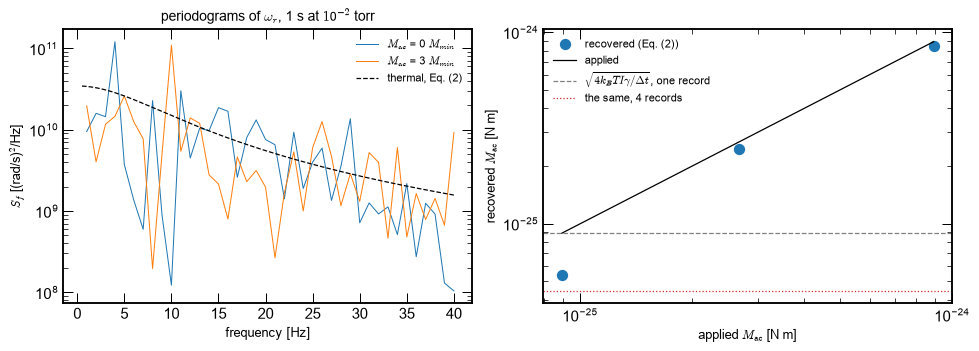

In [3]:
f, S = welch(np.concatenate(undriven), fs=1 / Δt, nperseg=2**19)
band = (f > 1) & (f < 200)
torque_noise = np.sqrt(S[band] * I**2 * ((2 * π * f[band])**2 + γ**2))
measured = np.sqrt(np.mean(torque_noise**2))
print(f'in silico torque sensitivity (1-200 Hz) at 1e-2 torr: {measured:.3e} N m/√Hz; '
      f'√(4kBTIγ) = {thermal_sensitivity(p_sim):.3e} (ratio {measured / thermal_sensitivity(p_sim):.3f})')
scaled = measured * np.sqrt(γ_rot(1e-5 * torr) / γ)
print(f'scaled to 1e-5 torr (γ ∝ p): {scaled:.2e} N m/√Hz; paper: thermal limit 3e-27, measured (4.2 ± 1.2)e-27 N m/√Hz')

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ax = axes[0]
for M_ac, M_est, fr, Sr in results[::2]:
    mask = (fr > 0.5) & (fr < 40)
    ax.semilogy(fr[mask], Sr[mask], lw=0.8, label=f'$M_{{ac}}$ = {M_ac / M_min_sim:.0f} $M_{{min}}$')
ff = np.linspace(0.5, 40, 400)
ax.semilogy(ff, 4 * kB * T * γ / (I * ((2 * π * ff)**2 + γ**2)), 'k--', label='thermal, Eq. (2)')
ax.set_xlabel('frequency [Hz]')
ax.set_ylabel(r'$S_f$ [(rad/s)$^2$/Hz]')
ax.set_title(r'periodograms of $\omega_r$, 1 s at $10^{-2}$ torr', fontsize=11)
ax.legend(frameon=False, fontsize=9)
ax = axes[1]
ax.loglog(amplitudes[1:], [r[1] for r in results[1:]], 'o', label='recovered (Eq. (2))')
ax.loglog(amplitudes[1:], amplitudes[1:], 'k-', lw=1, label='applied')
ax.axhline(M_min_sim, color='0.5', ls='--', label=r'$\sqrt{4k_BTI\gamma/\Delta t}$, one record')
ax.axhline(M_min_sim / np.sqrt(num_records), color='C3', ls=':', label=f'the same, {num_records} records')
ax.set_xlabel(r'applied $M_\mathrm{ac}$ [N m]')
ax.set_ylabel(r'recovered $M_\mathrm{ac}$ [N m]')
ax.legend(frameon=False, fontsize=9)
fig.tight_layout()

The recovered torque follows the applied one down to about the thermal floor of the averaged
records, with the statistical scatter of a periodogram bin, as in Fig. 3e of the paper. The rotational gas noise of levisim satisfies the
fluctuation-dissipation relation (the equipartition check), so the in-silico sensitivity is the
thermal limit.

## Summary

| Quantity | Paper | levisim | Verdict |
|---|---|---|---|
| thermal sensitivity √(4kBTIγ) at 10⁻⁵ torr, 300 K, 150 nm sphere | 3 × 10⁻²⁷ N m/√Hz (arXiv v1, with the measured γ) | 2.8 × 10⁻²⁷ N m/√Hz (Martinetz γ) | agree |
| sensitivity measured in silico (from simulated ω_r traces, scaled from 10⁻² torr by √p) | — | 2.9 × 10⁻²⁷ N m/√Hz (ratio 1.03 to the thermal limit at the simulated pressure) | equals the thermal limit within the statistics |
| measured sensitivity | (4.2 ± 1.2) × 10⁻²⁷ N m/√Hz (published; arXiv v1: 6 × 10⁻²⁷) | thermal limit 2.8 × 10⁻²⁷ | measured value 1.5× above the thermal limit, within ~1.2 σ: the experiment has extra (technical) noise that levisim does not model |
| smallest torque in 100 s | (1.2 ± 0.5) × 10⁻²⁷ N m (above the noise floor 6 × 10⁻²⁸ N m) | thermal M_min = 2.8 × 10⁻²⁸ N m | consistent: the measured floor is ~2× the thermal one |
| torque recovery with Eq. (2) | Fig. 3e | recovered ≈ applied down to the thermal floor (see the printout and figure) | agree |

Not reproduced: the GHz rotation itself (it needs the particle's absorption or anisotropy, see the
Reimann et al. notebook) and the vacuum-friction calculations of Fig. 4. The simulation runs at
10⁻² torr and relies on γ ∝ p to reach 10⁻⁵ torr.

In [4]:
print(f'computation time {time.time() - t_start:.1f} s')

computation time 79.1 s
